In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [2]:
house_cleaned = pd.read_csv("../data/processed/house_cleaned.csv")
house_cleaned.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
house_cleaned.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

### Separate features from target variable and split the dataset

In [6]:
x = house_cleaned.drop(columns=["median_house_value"])
y = house_cleaned["median_house_value"]

In [7]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [8]:
print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


### Analyze Multicollinearity

In [12]:
# 1. Select numerical features

numeric_features = x_train.select_dtypes(include=["int64", "float64"]).columns

x_train_numeric = x_train[numeric_features].copy()

print("Numerical features:")
print(list(x_train_numeric.columns))

Numerical features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']


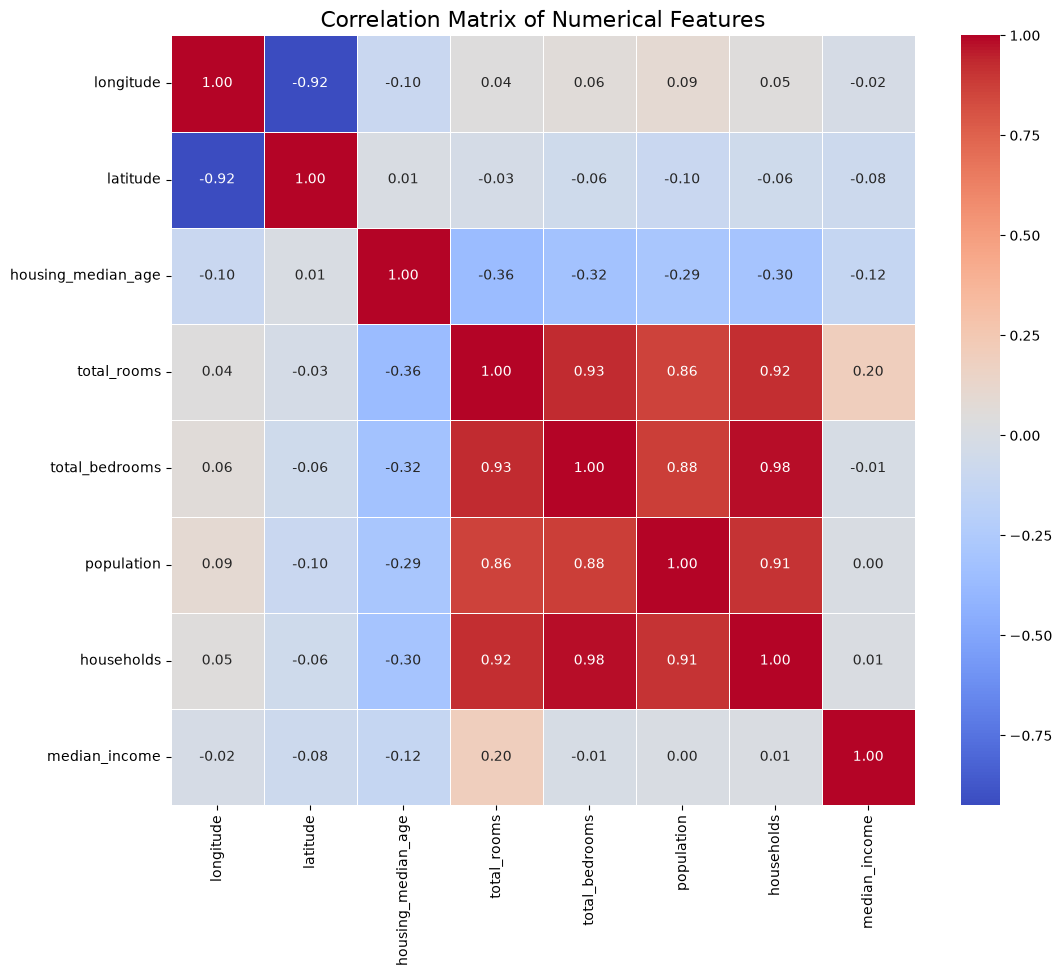

In [13]:
# 2. Calculate correlation matrix

correlation_matrix = x_train_numeric.corr()

plt.figure(figsize=(12,10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)

plt.title("Correlation Matrix of Numerical Features", fontsize=16)
plt.show()

In [14]:
# 3. Measure multicollinearity using Variance Inflation Factor (VIF)

vif_data = pd.DataFrame()

vif_data['Feature'] = x_train_numeric.columns

vif_data['VIF'] = [
    variance_inflation_factor(
        x_train_numeric.values,
        i
    )
    for i in range(x_train_numeric.shape[1])
]

vif_data = vif_data.sort_values(
    by='VIF',
    ascending=False
)

display(vif_data)

,Feature,VIF
4,total_bedrooms,36.307087
6,households,35.824564
3,total_rooms,12.821807
1,latitude,8.798267
0,longitude,8.681823
5,population,6.345431
7,median_income,1.740998
2,housing_median_age,1.257629
